# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170251          # <-- your full roll number
NAME = "Arnav"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170251   Name: Arnav   Fingerprint: 2F42E5E5   Tickets: 13

Ticket_ID                                                              Ticket_Text
      T01                                     Email me at helpdesk@university.edu.
      T02   VPN is not working after the latest update. Is there another solution?
      T03     Student portal was working yesterday during the lab. This is urgent.
      T04                                            Version 2.0.1 crashes at 99%.
      T05                  The lms has stopped syncing. I don't know what changed.
      T06   Password has stopped syncing after restarting the system. Please help.
      T07 The student portal keeps asking for login. It works on another computer.
      T08   I was locked out of the VPN when I use mobile hotspot. This is urgent.
      T09                                          Is it fixed?? Pls reply ASAP :(
      T10    I reinstalled the Matlab after restarting the system. This is urgent.
      T11 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
res = {}
rows = []
for tid, text in zip(df.Ticket_ID, df.Ticket_Text):
    r = process_ticket(text)
    res[tid] = r
    rows.append({"Ticket_ID": tid,
                 "Sentences": len(r["sentences"]),
                 "Tokens": len(r["tokens"]),
                 "Punctuation": len(r["punct"]),
                 "Stopwords": len(r["stops"]),
                 "Unique_Tokens": len(set(r["tokens"])),
                 "Final_Tokens": len(r["final"])})
q1 = pd.DataFrame(rows)
total = q1.drop(columns="Ticket_ID").sum()
q1.loc[len(q1)] = ["TOTAL"] + total.tolist()
print(q1.to_string(index=False))

sel = FOCUS[0]
print(f"\nSelected ticket: {sel}  ->  {df.set_index('Ticket_ID').loc[sel, 'Ticket_Text']}")
print("Tokens     :", res[sel]["tokens"])
print("Punctuation:", res[sel]["punct"])
print("Stopwords  :", res[sel]["stops"])
print("Final      :", res[sel]["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          1       7            2          2              7             3
      T02          2      14            2          6             13             6
      T03          2      13            2          5             12             6
      T04          1       7            2          1              7             4
      T05          2      13            2          5             12             6
      T06          2      12            2          3             11             7
      T07          2      14            2          4             13             8
      T08          2      17            2          9             15             6
      T09          2      10            4          2              9             4
      T10          2      13            2          6             11             5
      T11          2       9            2          2              8             5
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The non-words are `n't` (from "don't", "doesn't"), plus items like `pls`, `asap`, `lms`, `99` and `2.0.1`. `n't` comes from `word_tokenize` (Treebank style), which splits contractions into `do` + `n't` and `does` + `n't`. `do`/`does` are removed as stopwords, but `n't` is not in the NLTK stopword list, so it survives into the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

tickets = df.Ticket_Text.tolist()
alltext = " ".join(tickets)

LONG  = r"\b[A-Za-z]{6,}\b"
NUM   = r"\b\d+(?:[.,]\d+)*\b"
CAP   = r"\b[A-Z][a-z]+(?:-[A-Za-z]+)*\b"
VOWEL = r"\b[aeiou][a-z]*(?:'[a-z]+)?\b"

EMAIL = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+\b"
URL   = r"(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)]"
PHONE = r"(?<![\w.])(?:\+\d{1,3}[\s-]?)?\d{3,5}(?:[\s-]\d{3,5}){1,3}(?![\w])|(?<![\w.])\+?\d{10,13}(?![\w])"

def extract(text):
    return {"long(>5)": re.findall(LONG, text),
            "numbers": re.findall(NUM, text),
            "capitalized": re.findall(CAP, text),
            "vowel-start": re.findall(VOWEL, text, flags=re.I)}

def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text


print("=== re.findall on all raw tickets ===")
for k, v in extract(alltext).items():
    print(f"{k}: {v}\n")

print("=== re.findall on TEST_LINES ===")
for line in TEST_LINES:
    print(line)
    for k, v in extract(line).items():
        print(f"  {k}: {v}")

print("\n=== re.sub on tickets (changed ones) ===")
for tid, t in zip(df.Ticket_ID, tickets):
    if mask(t) != t:
        print(tid, "|", t, "\n    ->", mask(t))

print("\n=== re.sub on TEST_LINES ===")
for line in TEST_LINES:
    print(line, "\n  ->", mask(line))

# capitalized words that are capitalized only because they start a sentence
from nltk.tokenize import sent_tokenize
caps_total = len(re.findall(CAP, alltext))
caps_start = 0
for t in tickets:
    for s in sent_tokenize(t):
        if re.match(CAP, s):
            caps_start += 1
print("Capitalized words:", caps_total, "| only sentence-initial:", caps_start)

=== re.findall on all raw tickets ===
long(>5): ['helpdesk', 'university', 'working', 'latest', 'update', 'another', 'solution', 'Student', 'portal', 'working', 'yesterday', 'during', 'urgent', 'Version', 'crashes', 'stopped', 'syncing', 'changed', 'Password', 'stopped', 'syncing', 'restarting', 'system', 'Please', 'student', 'portal', 'asking', 'another', 'computer', 'locked', 'mobile', 'hotspot', 'urgent', 'reinstalled', 'Matlab', 'restarting', 'system', 'urgent', 'password', 'failed', 'Please', 'MATLAB', 'disconnecting', 'several']

numbers: ['2.0.1', '99']

capitalized: ['Email', 'Is', 'Student', 'This', 'Version', 'The', 'Password', 'Please', 'The', 'It', 'This', 'Is', 'Pls', 'Matlab', 'This', 'The', 'Please', 'The', 'The', 'Wi-Fi']

vowel-start: ['Email', 'at', 'university', 'edu', 'is', 'after', 'update', 'Is', 'another', 'is', 'urgent', 'at', 'I', 'after', 'asking', 'It', 'on', 'another', 'I', 'out', 'of', 'I', 'use', 'is', 'urgent', 'Is', 'it', 'ASAP', 'I', 'after', 'is', 'urg

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 20 capitalized words were found and 18 of them are capitalized only because they start a sentence (Email, Is, This, The, Please, ...). Only 2 are capitalized for another reason: `Wi-Fi` and `Matlab`.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

PATTERN = r"""
    [A-Za-z0-9._%+-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+              # email
  | (?:https?://|www\.)[^\s<>"']*[^\s<>"'.,;:!?)]                    # url
  | (?<![\w.])(?:\+\d{1,3}[\s-]?)?\d{3,5}(?:[\s-]\d{3,5}){1,3}(?![\w])   # phone
  | \d+(?:[.,]\d+)*(?!\w)                                           # integers, decimals, versions
  | (?:[A-Za-z]\.){2,}                                               # abbreviations like p.m.
  | \w+(?:[-'\u2019]\w+)*                                            # words, contractions, hyphenated
  | \.{2,}                                                          # ellipsis
  | [^\w\s]                                                         # any other punctuation
"""
_tok = RegexpTokenizer(PATTERN, flags=re.VERBOSE | re.UNICODE)

def my_tokenize(text):
    return _tok.tokenize(text)

print("=== TEST_LINES ===")
for line in TEST_LINES:
    print("mine :", my_tokenize(line))
    print("nltk :", word_tokenize(line), "\n")

print("=== Tickets: tickets where outputs differ ===")
diff_ids = []
for tid, t in zip(df.Ticket_ID, df.Ticket_Text):
    a, b = my_tokenize(t), word_tokenize(t)
    if a != b:
        diff_ids.append(tid)
        print(tid, "|", t)
        print("   only in my_tokenize   :", [x for x in a if x not in b])
        print("   only in word_tokenize :", [x for x in b if x not in a])
print(f"\nTickets tokenized differently: {len(diff_ids)} of {len(df)} -> {diff_ids}")

=== TEST_LINES ===
mine : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
nltk : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.'] 

mine : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
nltk : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.'] 

mine : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', "didn't", 'work', '.']
nltk : ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.'] 

=== Tickets: tickets where outputs differ ===
T01 | Email me at hel

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 3 of 13 tickets are tokenized differently: T01 (email kept whole by `my_tokenize`, split into `helpdesk`, `@`, `university.edu` by `word_tokenize`), T05 (`don't` vs `do` + `n't`) and T13 (`doesn't` vs `does` + `n't`).

On TEST_LINES the differences are bigger:
1. **URLs:** `my_tokenize` keeps `https://lms.thapar.edu/help` whole; `word_tokenize` breaks it into `https`, `:`, `//lms.thapar.edu/help`.
2. **Phone numbers:** `my_tokenize` keeps `+91 98765 43210` as one token; `word_tokenize` gives `+91`, `98765`, `43210`.
3. **Emails:** `it.helpdesk@thapar.edu` and `a.b-c@dept.univ.ac.in` stay whole in `my_tokenize` but are split around `@` by `word_tokenize`.
4. **Contractions:** `isn't`/`didn't` stay whole in `my_tokenize` but become `is` + `n't` and `did` + `n't` in `word_tokenize`.

Hyphenated words (`state-of-the-art`, `log-in`), decimals, versions and `p.m.` come out the same in both.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

unique_final = sorted({w for r in res.values() for w in r["final"]})

# POS tags from nltk.pos_tag, taken in the context of each ticket
pos_of = {}
for r in res.values():
    for w, tag in pos_tag(r["tokens"]):
        if w in unique_final and w not in pos_of:
            pos_of[w] = tag

def wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

# Suffix rule chosen from our data: working, syncing, restarting, disconnecting, asking (-ing)
# and stopped, locked, reinstalled, changed, failed, tried-type past forms (-ed)
porter, lancaster = PorterStemmer(), LancasterStemmer()
regexp = RegexpStemmer("ing$|ed$", min=4)
lemm = WordNetLemmatizer()

rows = []
for w in unique_final:
    rows.append({"word": w, "POS": pos_of[w], "porter": porter.stem(w), "lancaster": lancaster.stem(w),
                 "regexp": regexp.stem(w), "lemma": lemm.lemmatize(w, wn_pos(pos_of[w]))})
q4 = pd.DataFrame(rows)
differ = q4[q4[["porter", "lancaster", "regexp", "lemma"]].nunique(axis=1) > 1]
print(f"Unique final tokens: {len(q4)} | words with differing outputs: {len(differ)}\n")
print(differ.to_string(index=False))

Unique final tokens: 51 | words with differing outputs: 27

       word POS   porter lancaster    regexp     lemma
    another  DT    anoth     anoth   another   another
    changed VBD    chang     chang     chang    change
   computer  NN   comput    comput  computer  computer
    crashes NNS    crash     crash   crashes     crash
      keeps NNS     keep      keep     keeps      keep
     latest JJS   latest    latest    latest      late
        lms  NN       lm       lms       lms        lm
     mobile  JJ    mobil      mobl    mobile    mobile
       open  VB     open        op      open      open
     please  VB    pleas     pleas    please    please
        pls  NN       pl       pls       pls       pls
     portal  NN   portal      port    portal    portal
reinstalled VBD reinstal  reinstal reinstall reinstall
      reply  NN    repli     reply     reply     reply
    several  JJ    sever       sev   several   several
   solution  NN    solut      solv  solution  solution
    s

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Regexp stemmer rule: `ing$|ed$` (min length 4). It is based on our own words: `working`, `syncing`, `restarting`, `disconnecting`, `asking` (-ing) and `stopped`, `locked`, `reinstalled`, `changed`, `failed` (-ed). Both endings are very common in tickets, so one rule covers many words.

**Over-stemming:** Lancaster turns `solution` into `solv`, `version` into `vert` and `student` into `stud`; Porter turns `several` into `sever`. These cut away too much and change the meaning or merge unrelated words.

**Under-stemming:** the Regexp stemmer leaves `crashes`, `keeps` and `works` unchanged (they end in -s), so they are not merged with `crash`, `keep` and `work`. It also gives `stopp` for `stopped` (a leftover double letter).

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Set  Total  Unique    TTR
 S1    150      83 0.5533
 S2    122      75 0.6148
 S3     70      51 0.7286
 S4     70      50 0.7143

Top 10 S1: [('.', 19), ('the', 12), ('is', 6), ('i', 5), ('vpn', 3), ('after', 3), ('?', 3), ('this', 3), ('urgent', 3), ('at', 2)]
Top 10 S3: [('vpn', 3), ('urgent', 3), ('working', 2), ('another', 2), ('student', 2), ('portal', 2), ('stopped', 2), ('syncing', 2), ("n't", 2), ('password', 2)]


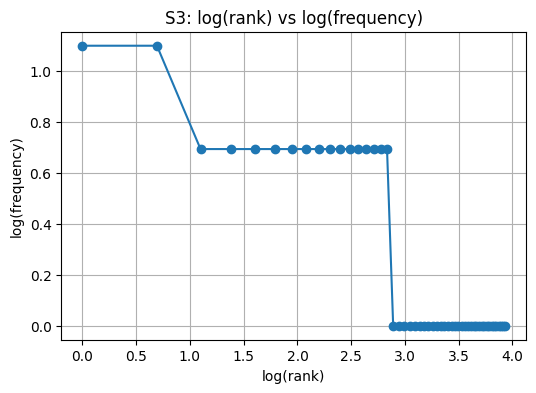

Top 5 bigrams S1: [(('.', 'this'), 3), (('this', 'is'), 3), (('is', 'urgent'), 3), (('urgent', '.'), 3), (('student', 'portal'), 2)]
Top 5 bigrams S3: [(('student', 'portal'), 2), (('stopped', 'syncing'), 2), (('restarting', 'system'), 2), (('please', 'help'), 2), (('email', 'helpdesk'), 1)]


In [9]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from nltk import bigrams

S1 = [t for r in res.values() for t in r["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for r in res.values() for t in r["final"]]
S4 = [porter.stem(t) for t in S3]

stats = pd.DataFrame([{"Set": n, "Total": len(s), "Unique": len(set(s)), "TTR": round(len(set(s)) / len(s), 4)}
                      for n, s in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]])
print(stats.to_string(index=False))

print("\nTop 10 S1:", Counter(S1).most_common(10))
print("Top 10 S3:", Counter(S3).most_common(10))

freq = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freq) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freq), "o-")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)"); plt.title("S3: log(rank) vs log(frequency)")
plt.grid(True); plt.show()

# bigrams are built inside each ticket so they do not cross ticket boundaries
bg1 = Counter(b for r in res.values() for b in bigrams(r["tokens"]))
bg3 = Counter(b for r in res.values() for b in bigrams(r["final"]))
print("Top 5 bigrams S1:", bg1.most_common(5))
print("Top 5 bigrams S3:", bg3.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* S1 → S2 → S3: TTR rises (0.553 → 0.615 → 0.729) because removing punctuation and stopwords deletes many repeated tokens (`.` appears 19 times, `the` 12 times), so the total drops much faster than the number of unique words. S3 → S4: TTR falls slightly (0.729 → 0.714) because Porter stemming merges variants (`working` and `works` both become `work`), so unique tokens go from 51 to 50 while the total stays at 70.

---
## Q6. Interpretation

**(a)** TTR rises from S1 to S3 because punctuation and stopwords (very repetitive tokens) are removed, which shrinks the total much more than the unique count. It dips from S3 to S4 because stemming merges word forms (`working`/`works` → `work`), reducing unique tokens while the total stays the same.

**(b)** For `I don't know what changed.`, `my_tokenize` gives `don't` as one token, while `word_tokenize` gives `do` and `n't`. Another: `helpdesk@university.edu` stays whole in `my_tokenize` but is split into `helpdesk`, `@`, `university.edu` by `word_tokenize`. The difference is that `word_tokenize` follows Treebank rules (split contractions, split `@`, `:`), while my single regex keeps `\w+(['-]\w+)*` and email/URL/phone patterns together.

**(c)** Porter stems `several` to `sever`, which looks like a different word with a different meaning. Lancaster is worse: `version` → `vert`, `solution` → `solv`. Also Porter `tried` → `tri` is not a real word.

**(d)** `tried` (a past participle): Porter gives `tri`, but the POS-aware lemmatizer (tag VBN → verb) gives `try`, a real word with the correct meaning. Likewise `changed` → `change` (Porter: `chang`) and `crashes` → `crash` (Regexp stemmer leaves `crashes`).